In [26]:

import os, sys, math, glob, json, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
from scipy.signal import welch, butter, filtfilt
from scipy.stats import kurtosis
import mne

# GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    try:
        print("GPU:", torch.cuda.get_device_name(0))
    except:
        pass


Device: cuda
GPU: NVIDIA GeForce GTX 1650 Ti


In [27]:
# Global plotting style
import seaborn as sns
sns.set(context='notebook', style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})


##Cell 2: Checking GPU Availability and Importing the dataset
1) Creates a Subjects Range from 1 to 66 patients  
2) sampling rate in dataset = 500 readings every second
3) 5-second windows --> cuts EEG data into 5-second pieces
4) 50% overlap --> 50% overlap between EEG segments
5) number of Channels = 19

In [28]:
##Cell 2
datasetPath = r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG"  
subjects = [f"sub-{i:03d}" for i in range(1,66)]  
fs_target = 500  # sampling rate in dataset (already 500)
seg_sec = 5      # 5-second windows
overlap = 0.5    # 50% overlap
window_samples = int(seg_sec * fs_target)
step_samples = int(window_samples * (1 - overlap))
n_channels_expected = 19
save_dir = Path("results_bilstm")
save_dir.mkdir(exist_ok=True)


In [29]:
# Cell 3: ueses wavelet-packet proxy

In [30]:
# Cell 3
use_tqwt = False
try:
    import tqwt  # preferred package if available
    use_tqwt = True
    print("tqwt package available.")
except Exception as e:
    print("tqwt not found. Will use fallback (wavelet-packet approx) if necessary.")
    use_tqwt = False

# Fallback: we'll use pywt WaveletPacket as approximate multi-band split when tqwt unavailable
try:
    import pywt
    has_pywt = True
except:
    has_pywt = False
    raise ImportError("pywt not installed. Please install pywt (pip install PyWavelets).")


tqwt not found. Will use fallback (wavelet-packet approx) if necessary.


Cell 4: 
This cell extracts useful information (features) from raw 
EEG signals so that the Bi-LSTM model can understand them better.
Entropy --> quantify the impurity, disorder, or uncertainty within a dataset.
1) shannon_entropy --> How random or unpredictable the EEG signal is
2) tsallis_entropy --> Finding rare spikes in EEG that normal measures might miss
3) renyi_entropy --> Measures how concentrated the EEG signal is
4) katz_fd --> Signal complexity,How rough or jagged the EEG signal is
5) kurtosis_feature --> Peakedness of the EEG signal

In [31]:
# Cell 4: feature functions
def shannon_entropy(x, bins=100):
    p, _ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return -np.sum(p * np.log2(p))

def tsallis_entropy(x, q=2.0, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    if q == 1.0:
        return -np.sum(p * np.log(p))
    return (1.0 - np.sum(p**q)) / (q - 1.0)

def renyi_entropy(x, q=0.5, bins=100):
    p,_ = np.histogram(x, bins=bins, density=True)
    p = p[p>0]
    return (1.0/(1.0 - q)) * np.log(np.sum(p**q))

def katz_fd(x):
    x = np.asarray(x)
    n = len(x)
    if n < 2:
        return 0.0
    L = np.sum(np.sqrt(1 + np.diff(x)**2))
    d = np.max(np.sqrt((np.arange(n) - 0)**2 + (x - x[0])**2))
    if L == 0 or d == 0:
        return 0.0
    return np.log10(n) / (np.log10(n) + np.log10(d / L))

def kurtosis_feature(x):
    return float(kurtosis(x, fisher=False, nan_policy='omit'))

# wrapper to compute 4 features from a 1D subband
def features_from_subband(x):
    x = np.asarray(x)
    if x.std() == 0:
        x = x - x.mean()
    return [katz_fd(x), tsallis_entropy(x, q=2.0), renyi_entropy(x, q=0.5), kurtosis_feature(x)]


In [32]:
# Cell 5: estimate Q,R,J from signal power (simple heuristic)
def estimate_tqwt_params(signal, fs):
    # PSD to find dominant freq f0 and approximate bandwidth
    f, Pxx = welch(signal, fs=fs, nperseg=min(len(signal), 2048))## Welches Methods 
    f0 = f[np.argmax(Pxx)]                                       ##Finds frequency with maximum power(This is the strongest brain rhythm)
    # half-power bandwidth approx
    peak = np.max(Pxx)
    inds = np.where(Pxx >= peak/2)[0]
    if len(inds) > 1:
        bw = f[inds[-1]] - f[inds[0]]
    else:
        bw = max(1.0, f0*0.5)
    Q = max(0.5, float(f0) / max(bw, 1e-6))
    # redundancy heuristic: bound between 2 and 12
    R = int(np.clip(fs / (2 * max(f0,1.0)), 2, 12))
    # J selection: want ~2 Hz subband width: J ~ log2((fs/2)/target_bw)
    target_bw = 2.0
    J = int(np.clip(np.floor(np.log2((fs/2)/target_bw)), 3, 8))
    return float(Q), int(R), int(J)

# quick test (won't run until dataset provided)
# print(estimate_tqwt_params(np.random.randn(1000), fs_target))


In [33]:
# Cell 6: decomposition function returning list of subband time-series (length J+1)
def decompose_tqwt(signal, Q, R, J, fs):
    # Try tqwt library if available
    if use_tqwt:
        try:
            # tqwt API vary. Example: tqwt.tqwt(signal, Q, r, J) -> coeffs or subbands
            coeffs = tqwt.tqwt(signal, Q, R, J)  # may require adaptation
            # user must adapt if API differs. We'll expect reconstructed subbands returned.
            return coeffs
        except Exception as e:
            pass
    # Fallback: use wavelet packet decomposition to produce J+1 components
    wp = pywt.WaveletPacket(data=signal, wavelet='db4', mode='symmetric', maxlevel=J)
    # Collect nodes at level J (details approximating bands)
    nodes = [node.path for node in wp.get_level(J, order='freq')]
    subbands = []
    for path in nodes:
        node_data = wp[path].data
        # Reconstruct node to full length via inverse transform on that node only
        # Simpler: upsample node_data to original length by interpolation
        up = np.interp(np.linspace(0, len(node_data)-1, len(signal)), np.arange(len(node_data)), node_data)
        subbands.append(up)
    # ensure we return exactly J+1 bands; if fewer, pad with zeros
    if len(subbands) < J+1:
        for _ in range(J+1 - len(subbands)):
            subbands.append(np.zeros_like(signal))
    return subbands[:J+1]


In [34]:
import pandas as pd
from pathlib import Path

data_root = Path(datasetPath)
label_file = Path(r"/media/shashank/307ADF5A7ADF1C02/EEG_Project/labels.xlsx")

# read Excel file
labels_df = pd.read_excel(label_file)

# clean column names
labels_df.columns = labels_df.columns.str.strip().str.lower()

# Normalize label text and build dictionary
labels = {}
for _, row in labels_df.iterrows():
    sid = str(row['subject']).strip()
    lab = str(row['label']).strip().lower()

    if 'a' in lab or 'alzheimer' in lab:
        labels[sid] = 1
    elif 'control' in lab or 'c' in lab or 'healthy' in lab:
        labels[sid] = 0
    elif lab in ['1', '0']:
        labels[sid] = int(lab)
    else:
        labels[sid] = None


# --- Build manifest: subject, EEG file path, label ---
manif = []

for sub in subjects:
    subdir = data_root / sub
    if not subdir.exists():
        subdir = next(data_root.glob(f"**/{sub}"), None)
        if subdir is None:
            print("Missing:", sub)
            continue

    eeg_files = list(subdir.glob("**/*.set")) + \
                list(subdir.glob("**/*.edf")) + \
                list(subdir.glob("**/*.bdf"))

    if not eeg_files:
        print("No EEG file for", sub)
        continue

    filepath = eeg_files[0]
    label = labels.get(sub, None)

    if label is None:
        print("Label missing for", sub, "- skipping.")
        continue

    manif.append((sub, str(filepath), int(label)))

print("Subjects collected:", len(manif))
print("Example:", manif[:3])



Subjects collected: 65
Example: [('sub-001', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-001/eeg/sub-001_task-eyesclosed_eeg.set', 1), ('sub-002', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-002/eeg/sub-002_task-eyesclosed_eeg.set', 1), ('sub-003', '/media/shashank/307ADF5A7ADF1C02/EEG_Project/EEG/eeg/sub-003/eeg/sub-003_task-eyesclosed_eeg.set', 1)]


/tmp/ipykernel_17202/3569509094.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=df_manif, palette='viridis')


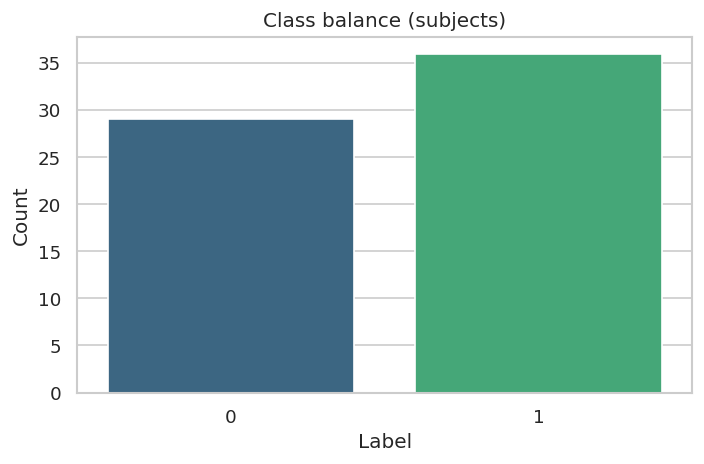

   subject                                           filepath  label
0  sub-001  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
1  sub-002  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
2  sub-003  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
3  sub-004  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1
4  sub-005  /media/shashank/307ADF5A7ADF1C02/EEG_Project/E...      1


In [35]:
# Diagnostic: class balance of subjects (manifest)
import pandas as _pd
df_manif = _pd.DataFrame(manif, columns=['subject','filepath','label'])
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=df_manif, palette='viridis')
plt.xlabel('Label'); plt.ylabel('Count'); plt.title('Class balance (subjects)')
plt.tight_layout()
plt.savefig(save_dir / 'class_balance_subjects.png', dpi=150)
plt.show()

# show first few manifest entries for quick inspection
print(df_manif.head())


In [ ]:
# Cell 8: segmentation and live TQWT feature extraction (fixed)

def bandpass(x, lo=0.5, hi=45, fs=fs_target, order=4):
    b, a = butter(order, [lo/(fs/2), hi/(fs/2)], btype='band')
    return filtfilt(b, a, x)

all_features = []
all_labels = []
all_subject_idx = []

for subj_idx, (sub, filepath, label) in enumerate(manif):
    print(f"\nProcessing {sub} ({subj_idx+1}/{len(manif)}) label={label}")

    # --- Load EEG (.set) safely ---
    try:
        raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')
    except Exception:
        raw = mne.io.read_raw_eeglab(filepath, preload=False, verbose='ERROR')
        raw.load_data()

    raw.pick_types(eeg=True)
    data = raw.get_data()
    n_ch, n_samps = data.shape
    fs = raw.info['sfreq']

    # --- Bandpass filter (0.5–45 Hz) ---
    for ci in range(n_ch):
        data[ci] = bandpass(data[ci], 0.5, 45, fs)

    # --- Segment into 5s windows (50% overlap) ---
    total_segments = 0
    for start in range(0, int(n_samps - window_samples), step_samples):
        end = start + window_samples
        if end > n_samps:
            break
        seg = data[:, start:end]
        if seg.shape[1] < window_samples:
            continue

        total_segments += 1
        # Estimate data-driven TQWT parameters (Q, R, J)
        Q, R, J = estimate_tqwt_params(seg[0], fs)
        seg_feats = []

        # --- TQWT decomposition and feature extraction ---
        for ch in range(n_ch):
            subbands = decompose_tqwt(seg[ch], Q, R, J, fs)
            for sb in subbands:
                seg_feats.extend(features_from_subband(sb))

        expected_len = (J + 1) * 4 * n_channels_expected
        if len(seg_feats) < expected_len:
            seg_feats += [0.0] * (expected_len - len(seg_feats))

        all_features.append(seg_feats)
        all_labels.append(label)
        all_subject_idx.append(sub)

    print(f"{sub}: {total_segments} segments extracted.")

    # --- Save checkpoint every 5 subjects ---
    if (subj_idx + 1) % 5 == 0:
        np.save(save_dir / "features_checkpoint.npy", np.array(all_features, dtype=object))
        pd.DataFrame({"label": all_labels, "sub": all_subject_idx}).to_csv(
            save_dir / "labels_checkpoint.csv", index=False
        )

print("\nFeature extraction done. Total segments:", len(all_features))
X = np.array(all_features, dtype=np.float32)
y = np.array(all_labels, dtype=np.int64)
print("X shape:", X.shape, "y shape:", y.shape)



Processing sub-001 (1/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-001: 238 segments extracted.

Processing sub-002 (2/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-002: 316 segments extracted.

Processing sub-003 (3/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-003: 121 segments extracted.

Processing sub-004 (4/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-004: 281 segments extracted.

Processing sub-005 (5/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-005: 320 segments extracted.

Processing sub-006 (6/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-006: 253 segments extracted.

Processing sub-007 (7/65) label=1
NOTE: pick_types() is a legacy function. New code should use inst.pick(...).
sub-007: 306 segme

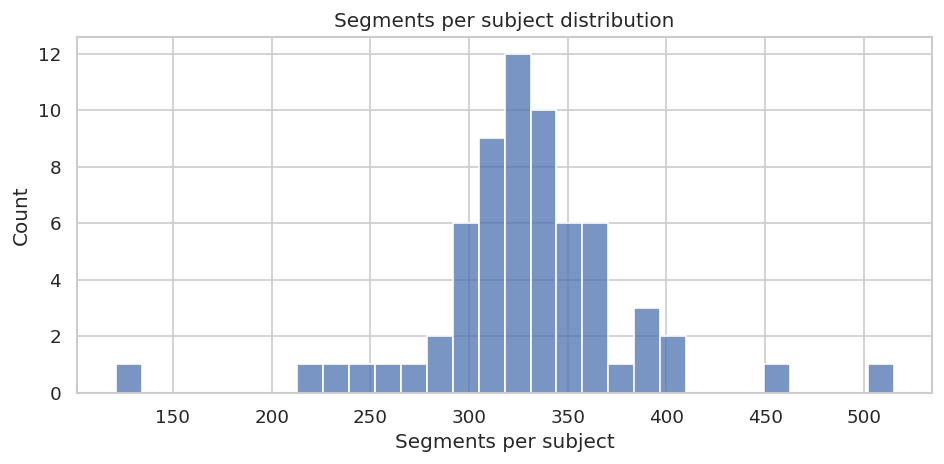

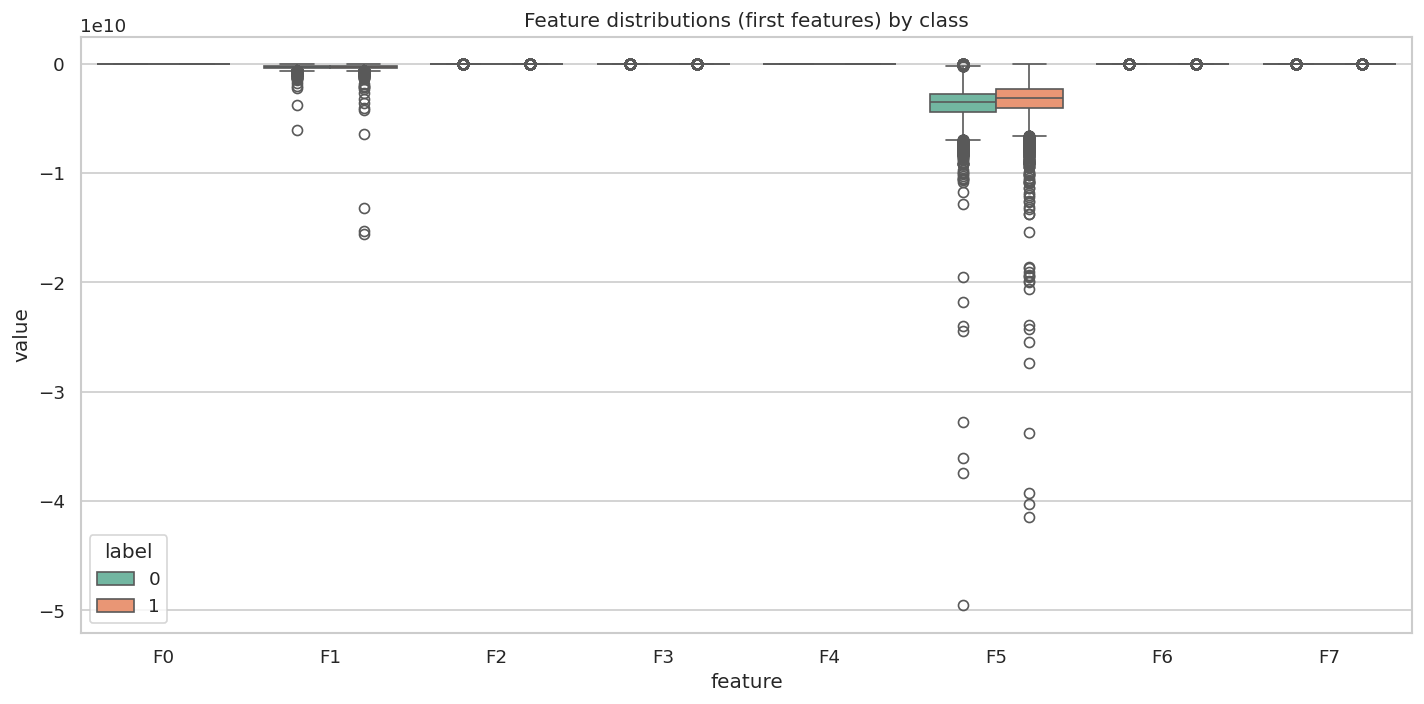

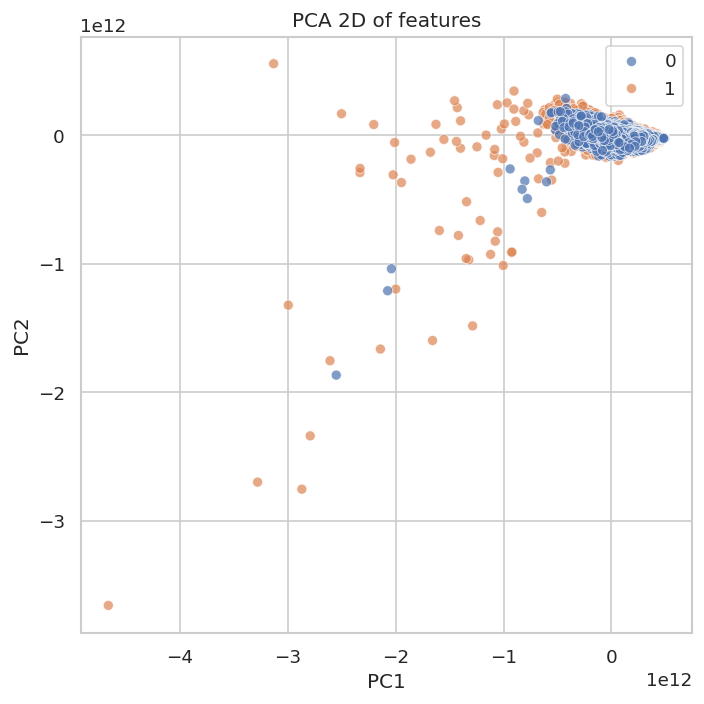

In [ ]:
# Diagnostics: segments per subject, feature distributions and PCA
import seaborn as sns
from collections import Counter
from sklearn.decomposition import PCA
# segments per subject
seg_counts = Counter(all_subject_idx)
subj_df = pd.DataFrame.from_dict(seg_counts, orient='index', columns=['segments']).reset_index()
subj_df.columns = ['subject','segments']
plt.figure(figsize=(8,4))
sns.histplot(subj_df['segments'], bins=30, kde=False)
plt.xlabel('Segments per subject'); plt.title('Segments per subject distribution')
plt.tight_layout()
plt.savefig(save_dir / 'segments_per_subject.png', dpi=150)
plt.show()

# boxplot of first few features by class
num_features = X.shape[1]
num_show = min(8, num_features)
feat_idx = list(range(num_show))
feat_df = pd.DataFrame(X[:,feat_idx], columns=[f'F{i}' for i in feat_idx])
feat_df['label'] = y
melt = feat_df.melt(id_vars='label', var_name='feature', value_name='value')
plt.figure(figsize=(12,6))
sns.boxplot(x='feature', y='value', hue='label', data=melt, palette='Set2')
plt.title('Feature distributions (first features) by class')
plt.tight_layout()
plt.savefig(save_dir / 'feature_boxplots.png', dpi=150)
plt.show()

# PCA 2D scatter
pca = PCA(n_components=2)
X2 = pca.fit_transform(X)
plt.figure(figsize=(6,6))
sns.scatterplot(x=X2[:,0], y=X2[:,1], hue=y, palette='deep', alpha=0.7)
plt.title('PCA 2D of features'); plt.xlabel('PC1'); plt.ylabel('PC2')
plt.tight_layout()
plt.savefig(save_dir / 'pca_features.png', dpi=150)
plt.show()


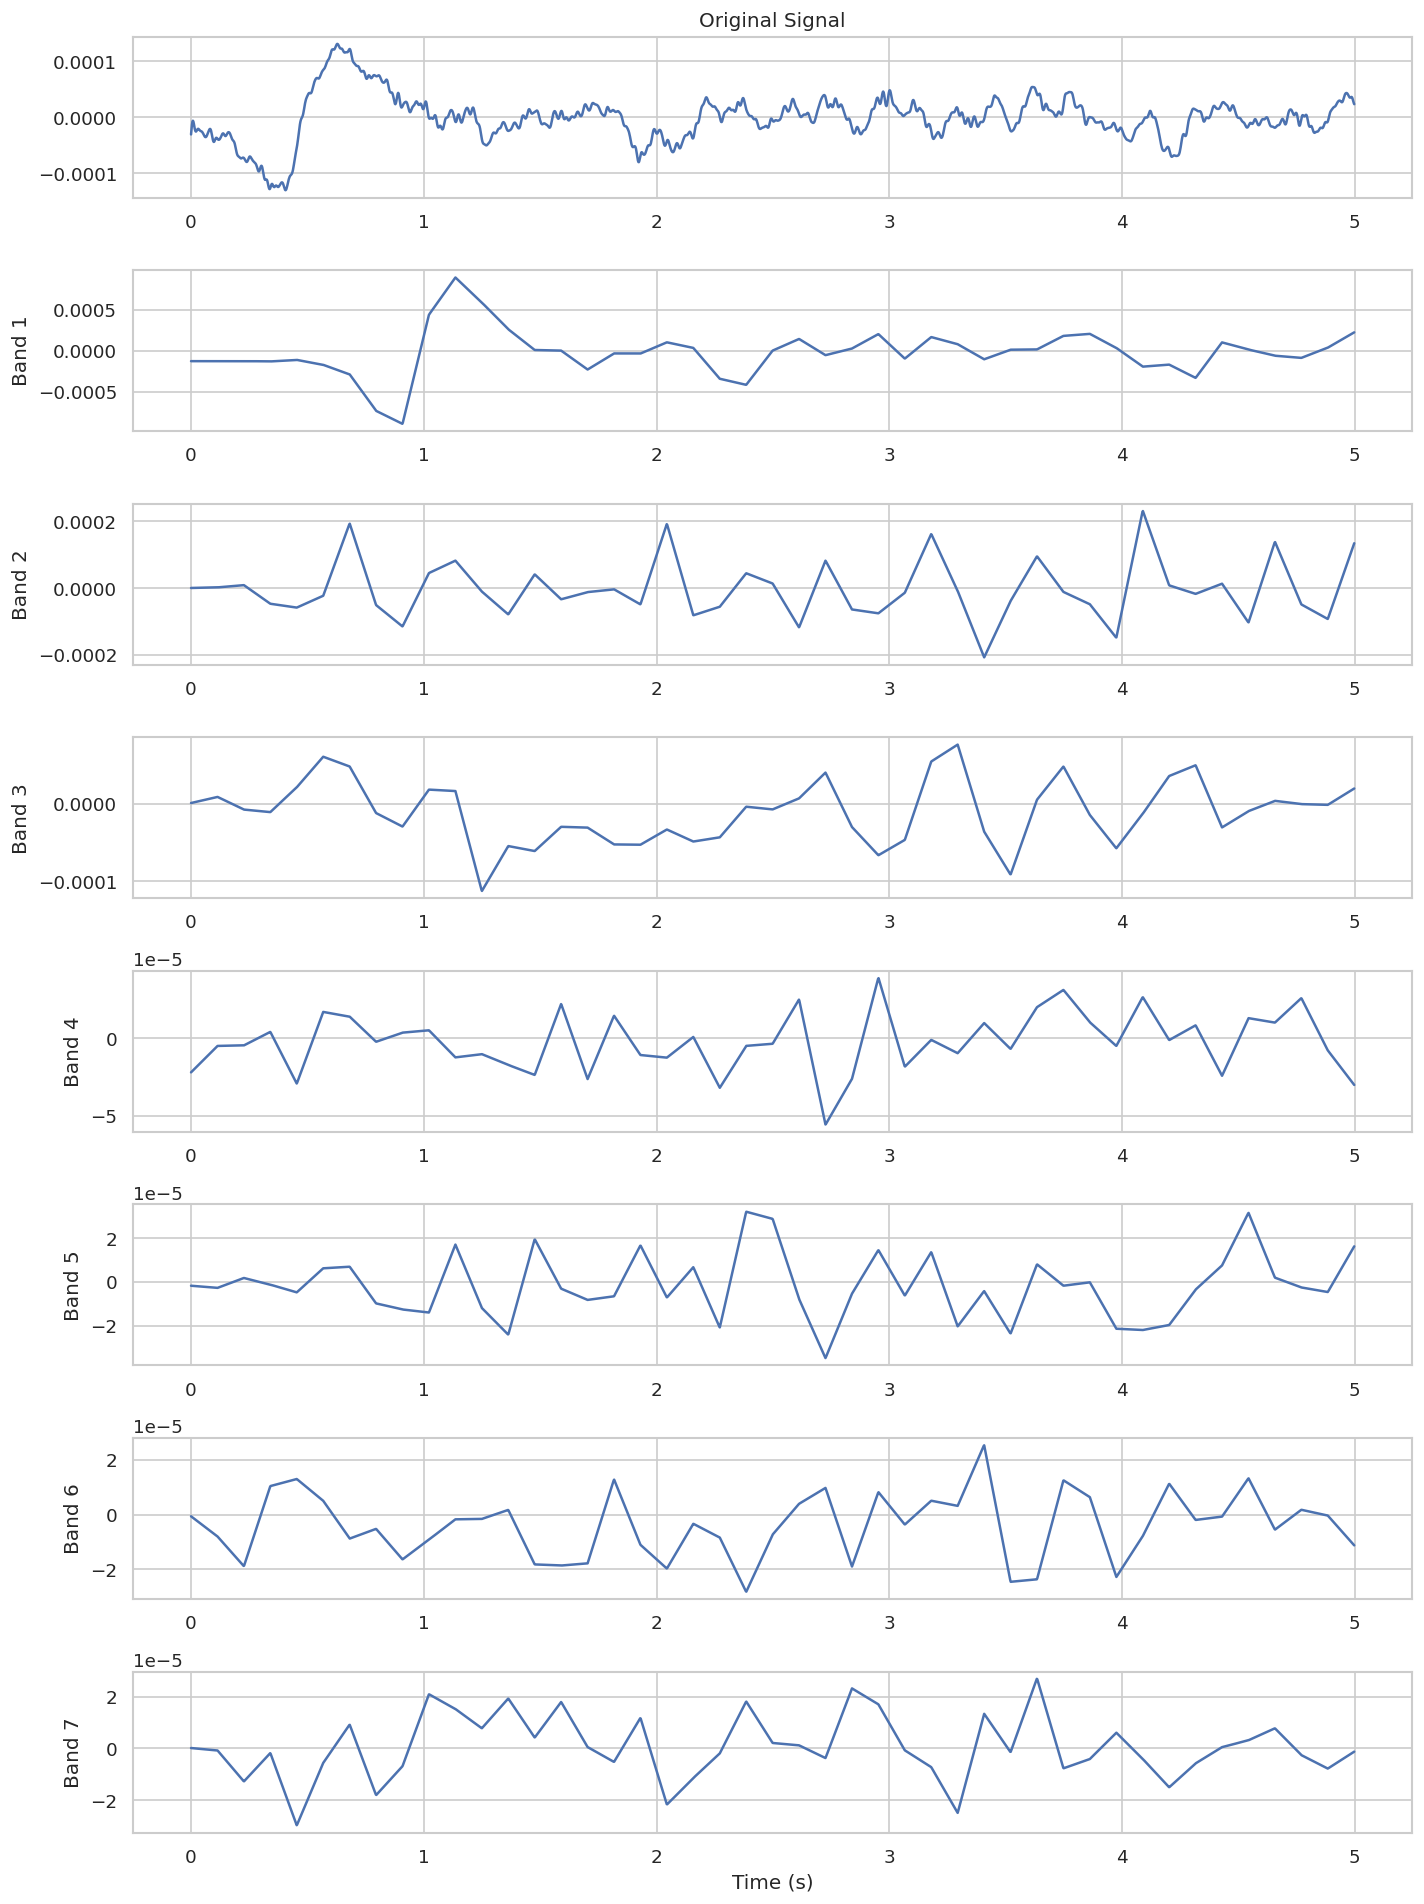

In [ ]:
# Visualization: signal + TQWT subbands

# load one subject just for visualization
sub, filepath, label = manif[0]
raw = mne.io.read_raw_eeglab(filepath, preload=True, verbose='ERROR')

data = raw.get_data()
sig = data[0]  # first channel
sig = bandpass(sig)

segment = sig[:window_samples]

Q, R, J = estimate_tqwt_params(segment, fs_target)
bands = decompose_tqwt(segment, Q, R, J, fs_target)

def plot_decomposition(signal, subbands, fs=fs_target):
    t = np.arange(len(signal)) / fs
    n = len(subbands) + 1

    plt.figure(figsize=(12, 2*n))

    plt.subplot(n,1,1)
    plt.plot(t, signal)
    plt.title("Original Signal")

    for i, band in enumerate(subbands):
        plt.subplot(n,1,i+2)
        plt.plot(t, band)
        plt.ylabel(f"Band {i+1}")

    plt.xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

plot_decomposition(segment, bands)


In [ ]:
# Cell 9: PyTorch Dataset
class EEGFeatureDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)
        self.y = torch.from_numpy(y)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# standardize features (fit on all for now; better: fit on train in CV loop)
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_scaled = sc.fit_transform(X)
np.save(save_dir/"scaler_mean.npy", sc.mean_)
np.save(save_dir/"scaler_scale.npy", sc.scale_)

dataset = EEGFeatureDataset(X_scaled, y)


In [ ]:
# Cell 10: mixup augmentation + simple feature-level augmentation
def mixup_data(x, y, alpha=0.4):
    '''Returns mixed inputs, pairs of targets, and lambda'''
    if alpha <= 0:
        return x, y, 1.0
    lam = np.random.beta(alpha, alpha)
    batch_size = x.size()[0]
    index = torch.randperm(batch_size).to(x.device)
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

def augment_features(x, noise_std=0.01, channel_dropout_p=0.1, timesteps=None):
    """Apply small gaussian noise and random channel (timestep) dropout to feature tensor.
    x: tensor shape (B, input_dim)
    timesteps: number of sequence timesteps to consider (will reshape to B, T, F)
    """
    if timesteps is None:
        return x
    b, d = x.shape
    feat_per_step = d // timesteps
    xv = x.view(b, timesteps, feat_per_step)
    # gaussian noise
    if noise_std > 0:
        noise = torch.randn_like(xv) * noise_std
        xv = xv + noise
    # channel / timestep dropout
    if channel_dropout_p > 0:
        mask = (torch.rand((b, timesteps, 1), device=xv.device) > channel_dropout_p).float()
        xv = xv * mask
    return xv.view(b, d)


In [ ]:
# Cell 11: BiLSTM classifier
class BiLSTMClassifier(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, n_layers=2, dropout=0.5):
        super().__init__()
        self.input_dim = input_dim
        self.hidden_dim = hidden_dim
        self.n_layers = n_layers
        # treat features as a sequence by splitting into "timesteps"
        # choose a timestep length: we can partition features into channels*subbands steps
        # We'll set timesteps = n_channels_expected and features_per_step = input_dim / timesteps
        self.timesteps = n_channels_expected
        assert input_dim % self.timesteps == 0, "input_dim must be divisible by timesteps"
        self.feat_per_step = input_dim // self.timesteps
        self.lstm = nn.LSTM(self.feat_per_step, hidden_dim, num_layers=n_layers,
                            batch_first=True, bidirectional=True, dropout=dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim*2, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        # x: batch x input_dim
        b = x.size(0)
        x = x.view(b, self.timesteps, self.feat_per_step)  # batch x timesteps x feat_per_step
        out, _ = self.lstm(x)  # batch x timesteps x (2*hidden_dim)
        # use last timestep
        out = out[:, -1, :]
        out = self.fc(out).squeeze(1)
        return out  # logits


In [ ]:
# Cell 12: training + 10-fold CV (GroupKFold by subject to avoid leakage)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupKFold

# groups: subject id for each segment (built during feature extraction)
groups = np.array(all_subject_idx)

# we'll use raw X (unscaled) and fit scaler per-fold to avoid leakage
INPUT_DIM = X.shape[1]
EPOCHS = 80
BATCH = 64
best_overall = {"auc":0.0, "model_path": None}

fold = 0
results = []

gkf = GroupKFold(n_splits=10)
for train_idx, test_idx in gkf.split(X, y, groups=groups):
    fold += 1
    print(f"\n===== Fold {fold} =====")
    X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    # compute class weights for criterion
    cw = compute_class_weight(class_weight='balanced', classes=np.unique(y_train), y=y_train)
    weight_tensor = torch.tensor([cw[0], cw[1]]).float().to(device)  # not directly used in BCEWithLogits
    # use pos_weight in BCEWithLogits for binary imbalance: pos_weight = weight of positive class
    # derive pos_weight = cw[1] / cw[0]
    pos_weight = torch.tensor([cw[1]/cw[0]]).float().to(device)

    train_ds = EEGFeatureDataset(X_train, y_train)
    test_ds = EEGFeatureDataset(X_test, y_test)
    train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True, drop_last=True)
    test_loader = DataLoader(test_ds, batch_size=BATCH, shuffle=False)

    model = BiLSTMClassifier(INPUT_DIM, hidden_dim=128, n_layers=2, dropout=0.5).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, 'max', patience=5, factor=0.5)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)  # handles imbalance

    best_auc = 0.0
    best_model_path = save_dir / f"best_fold{fold}.pt"
    early_stop_count = 0
    history = {'train_loss': [], 'val_auc': []}

    for epoch in range(1, EPOCHS+1):
        model.train()
        epoch_loss = 0.0
        all_preds = []
        all_targets = []
        for xb, yb in train_loader:
            xb = xb.to(device).float()
            yb = yb.to(device).float()
            # feature-level augmentation (noise + channel dropout)
            xb = augment_features(xb, noise_std=0.01, channel_dropout_p=0.1, timesteps=model.timesteps)
            # mixup
            xb, ya, yb2, lam = mixup_data(xb, yb.long(), alpha=0.6)
            xb, ya, yb2 = xb.to(device).float(), ya.to(device).float(), yb2.to(device).float()
            optimizer.zero_grad()
            logits = model(xb)
            loss = mixup_criterion(criterion, logits, ya, yb2, lam)
            loss.backward()
            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            epoch_loss += loss.item()*xb.size(0)
            preds = torch.sigmoid(logits).detach().cpu().numpy()
            all_preds.extend(preds.tolist())
            all_targets.extend(ya.detach().cpu().numpy().tolist())
        epoch_loss /= len(train_loader.dataset)
        # eval
        model.eval()
        y_true = []
        y_score = []
        with torch.no_grad():
            for xb, yb in test_loader:
                xb = xb.to(device).float()
                logits = model(xb)
                probs = torch.sigmoid(logits).detach().cpu().numpy()
                y_score.extend(probs.tolist())
                y_true.extend(yb.numpy().tolist())
        # compute AUC
        try:
            auc = roc_auc_score(y_true, y_score)
        except:
            auc = 0.5
        print(f"Fold{fold} Epoch {epoch:02d} loss:{epoch_loss:.4f} val_auc:{auc:.4f}")
        scheduler.step(auc)
        # record history
        history['train_loss'].append(epoch_loss)
        history['val_auc'].append(auc)

        # checkpoint
        if auc > best_auc:
            torch.save(model.state_dict(), best_model_path)
            best_auc = auc
            early_stop_count = 0
        else:
            early_stop_count += 1
        if early_stop_count >= 8:
            print("Early stopping.")
            break

    # load best model for fold and evaluate detailed metrics
    model.load_state_dict(torch.load(best_model_path))
    model.eval()
    y_true = []
    y_score = []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device).float()
            logits = model(xb)
            probs = torch.sigmoid(logits).detach().cpu().numpy()
            y_score.extend(probs.tolist())
            y_true.extend(yb.numpy().tolist())
    y_pred = [1 if p>=0.5 else 0 for p in y_score]
    auc = roc_auc_score(y_true, y_score)
    cm = confusion_matrix(y_true, y_pred)
    crep = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    results.append({"fold":fold, "auc":auc, "cm":cm, "report":crep, "model_path":str(best_model_path), 'history': history})
    print("Fold", fold, "AUC", auc, "CM\n", cm)
    # track best overall
    if auc > best_overall["auc"]:
        best_overall["auc"] = auc
        best_overall["model_path"] = str(best_model_path)

# save results summary
import pickle
with open(save_dir/"cv_results.pkl", "wb") as f:
    pickle.dump(results, f)
print("CV done. Best overall AUC:", best_overall["auc"], "model:", best_overall["model_path"])



===== Fold 1 =====
Fold1 Epoch 01 loss:0.5760 val_auc:0.8047
Fold1 Epoch 02 loss:0.5372 val_auc:0.8449
Fold1 Epoch 03 loss:0.5089 val_auc:0.8817
Fold1 Epoch 04 loss:0.4875 val_auc:0.8870
Fold1 Epoch 05 loss:0.4748 val_auc:0.9013
Fold1 Epoch 06 loss:0.4719 val_auc:0.9147
Fold1 Epoch 07 loss:0.4636 val_auc:0.9197
Fold1 Epoch 08 loss:0.4615 val_auc:0.9203
Fold1 Epoch 09 loss:0.4562 val_auc:0.9223
Fold1 Epoch 10 loss:0.4504 val_auc:0.9270
Fold1 Epoch 11 loss:0.4501 val_auc:0.9317
Fold1 Epoch 12 loss:0.4375 val_auc:0.9348
Fold1 Epoch 13 loss:0.4303 val_auc:0.9428
Fold1 Epoch 14 loss:0.4363 val_auc:0.9390
Fold1 Epoch 15 loss:0.4364 val_auc:0.9401
Fold1 Epoch 16 loss:0.4230 val_auc:0.9423
Fold1 Epoch 17 loss:0.4314 val_auc:0.9407
Fold1 Epoch 18 loss:0.4265 val_auc:0.9438
Fold1 Epoch 19 loss:0.4198 val_auc:0.9423
Fold1 Epoch 20 loss:0.4074 val_auc:0.9467
Fold1 Epoch 21 loss:0.4095 val_auc:0.9491
Fold1 Epoch 22 loss:0.4182 val_auc:0.9524
Fold1 Epoch 23 loss:0.4075 val_auc:0.9540
Fold1 Epoch 24

/tmp/ipykernel_17202/1716271859.py:98: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold2 Epoch 01 loss:0.5695 val_auc:0.7671
Fold2 Epoch 02 loss:0.5375 val_auc:0.8272
Fold2 Epoch 03 loss:0.5149 val_auc:0.8677
Fold2 Epoch 04 loss:0.4920 val_auc:0.8901
Fold2 Epoch 05 loss:0.4786 val_auc:0.8967
Fold2 Epoch 06 loss:0.4836 val_auc:0.9046
Fold2 Epoch 07 loss:0.4694 val_auc:0.9075
Fold2 Epoch 08 loss:0.4532 val_auc:0.9222
Fold2 Epoch 09 loss:0.4552 val_auc:0.9234
Fold2 Epoch 10 loss:0.4497 val_auc:0.9263
Fold2 Epoch 11 loss:0.4481 val_auc:0.9351
Fold2 Epoch 12 loss:0.4398 val_auc:0.9372
Fold2 Epoch 13 loss:0.4304 val_auc:0.9415
Fold2 Epoch 14 loss:0.4299 val_auc:0.9446
Fold2 Epoch 15 loss:0.4299 val_auc:0.9478
Fold2 Epoch 16 loss:0.4244 val_auc:0.9453
Fold2 Epoch 17 loss:0.4206 val_auc:0.9511
Fold2 Epoch 18 loss:0.4221 val_auc:0.9548
Fold2 Epoch 19 loss:0.4077 val_auc:0.9542
Fold2 Epoch 20 loss:0.4119 val_auc:0.9531
Fold2 Epoch 21 loss:0.4089 val_auc:0.9585
Fold2 Epoch 22 loss:0.4077 val_auc:0.9547
Fold2 Epoch 23 loss:0.4075 val_auc:0.9593
Fold2 Epoch 24 loss:0.4065 val_auc

/tmp/ipykernel_17202/1716271859.py:98: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold3 Epoch 01 loss:0.5770 val_auc:0.7650
Fold3 Epoch 02 loss:0.5353 val_auc:0.8522
Fold3 Epoch 03 loss:0.5108 val_auc:0.8807
Fold3 Epoch 04 loss:0.4877 val_auc:0.8908
Fold3 Epoch 05 loss:0.4795 val_auc:0.9000
Fold3 Epoch 06 loss:0.4721 val_auc:0.9113
Fold3 Epoch 07 loss:0.4621 val_auc:0.9133
Fold3 Epoch 08 loss:0.4615 val_auc:0.9152
Fold3 Epoch 09 loss:0.4562 val_auc:0.9228
Fold3 Epoch 10 loss:0.4485 val_auc:0.9250
Fold3 Epoch 11 loss:0.4441 val_auc:0.9338
Fold3 Epoch 12 loss:0.4469 val_auc:0.9387
Fold3 Epoch 13 loss:0.4331 val_auc:0.9374
Fold3 Epoch 14 loss:0.4276 val_auc:0.9390
Fold3 Epoch 15 loss:0.4417 val_auc:0.9417
Fold3 Epoch 16 loss:0.4221 val_auc:0.9441
Fold3 Epoch 17 loss:0.4304 val_auc:0.9439
Fold3 Epoch 18 loss:0.4219 val_auc:0.9537
Fold3 Epoch 19 loss:0.4077 val_auc:0.9527
Fold3 Epoch 20 loss:0.4180 val_auc:0.9504
Fold3 Epoch 21 loss:0.4166 val_auc:0.9529
Fold3 Epoch 22 loss:0.4079 val_auc:0.9544
Fold3 Epoch 23 loss:0.4076 val_auc:0.9607
Fold3 Epoch 24 loss:0.4011 val_auc

...

/tmp/ipykernel_17202/1716271859.py:98: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold9 Epoch 01 loss:0.5747 val_auc:0.8167
Fold9 Epoch 02 loss:0.5356 val_auc:0.8600
Fold9 Epoch 03 loss:0.5093 val_auc:0.8869
Fold9 Epoch 04 loss:0.4932 val_auc:0.8893
Fold9 Epoch 05 loss:0.4823 val_auc:0.9071
Fold9 Epoch 06 loss:0.4812 val_auc:0.9132
Fold9 Epoch 07 loss:0.4734 val_auc:0.9191
Fold9 Epoch 08 loss:0.4585 val_auc:0.9270
Fold9 Epoch 09 loss:0.4531 val_auc:0.9289
Fold9 Epoch 10 loss:0.4519 val_auc:0.9403
Fold9 Epoch 11 loss:0.4471 val_auc:0.9387
Fold9 Epoch 12 loss:0.4449 val_auc:0.9448
Fold9 Epoch 13 loss:0.4428 val_auc:0.9433
Fold9 Epoch 14 loss:0.4337 val_auc:0.9431
Fold9 Epoch 15 loss:0.4429 val_auc:0.9484
Fold9 Epoch 16 loss:0.4274 val_auc:0.9498
Fold9 Epoch 17 loss:0.4191 val_auc:0.9470
Fold9 Epoch 18 loss:0.4167 val_auc:0.9531
Fold9 Epoch 19 loss:0.4151 val_auc:0.9563
Fold9 Epoch 20 loss:0.4093 val_auc:0.9557
Fold9 Epoch 21 loss:0.4170 val_auc:0.9585
Fold9 Epoch 22 loss:0.4166 val_auc:0.9515
Fold9 Epoch 23 loss:0.4104 val_auc:0.9605
Fold9 Epoch 24 loss:0.4095 val_auc

/tmp/ipykernel_17202/1716271859.py:98: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Fold10 Epoch 01 loss:0.5722 val_auc:0.8030
Fold10 Epoch 02 loss:0.5303 val_auc:0.8525
Fold10 Epoch 03 loss:0.5066 val_auc:0.8879
Fold10 Epoch 04 loss:0.4883 val_auc:0.8940
Fold10 Epoch 05 loss:0.4840 val_auc:0.9045
Fold10 Epoch 06 loss:0.4716 val_auc:0.9049
Fold10 Epoch 07 loss:0.4671 val_auc:0.9126
Fold10 Epoch 08 loss:0.4648 val_auc:0.9183
Fold10 Epoch 09 loss:0.4502 val_auc:0.9302
Fold10 Epoch 10 loss:0.4504 val_auc:0.9235
Fold10 Epoch 11 loss:0.4463 val_auc:0.9344
Fold10 Epoch 12 loss:0.4390 val_auc:0.9401
Fold10 Epoch 13 loss:0.4380 val_auc:0.9423
Fold10 Epoch 14 loss:0.4295 val_auc:0.9430
Fold10 Epoch 15 loss:0.4265 val_auc:0.9461
Fold10 Epoch 16 loss:0.4219 val_auc:0.9467
Fold10 Epoch 17 loss:0.4256 val_auc:0.9507
Fold10 Epoch 18 loss:0.4127 val_auc:0.9460
Fold10 Epoch 19 loss:0.4076 val_auc:0.9534
Fold10 Epoch 20 loss:0.4101 val_auc:0.9560
Fold10 Epoch 21 loss:0.4121 val_auc:0.9568
Fold10 Epoch 22 loss:0.4075 val_auc:0.9580
Fold10 Epoch 23 loss:0.3913 val_auc:0.9570
Fold10 Epoc

/tmp/ipykernel_17202/1716271859.py:98: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


/tmp/ipykernel_17202/325129476.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(range(1,len(aucs)+1)), y=aucs, palette='viridis')


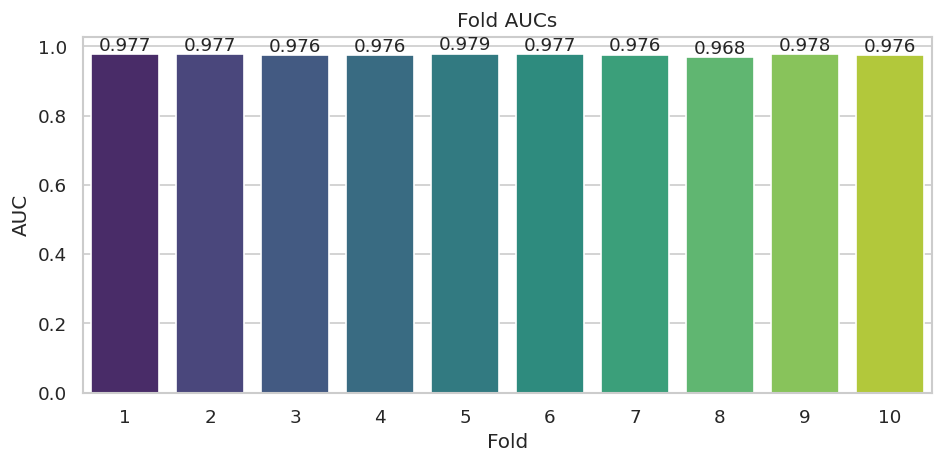

Best fold: 5 AUC: 0.9791796255882033
Classification report (best fold):
              precision    recall  f1-score      support
0              0.917088  0.933128  0.925038   972.000000
1              0.943674  0.929974  0.936774  1171.000000
accuracy       0.931405  0.931405  0.931405     0.931405
macro avg      0.930381  0.931551  0.930906  2143.000000
weighted avg   0.931615  0.931405  0.931451  2143.000000


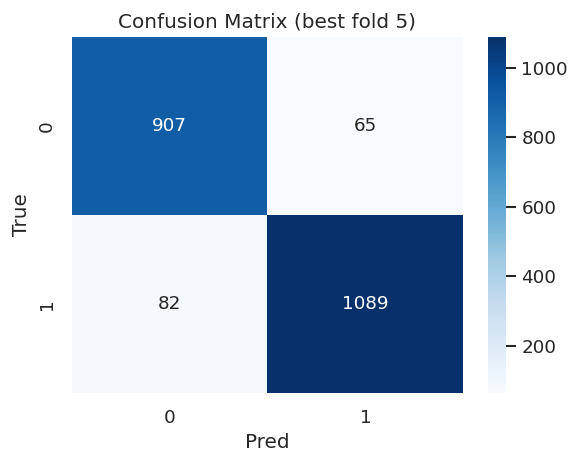

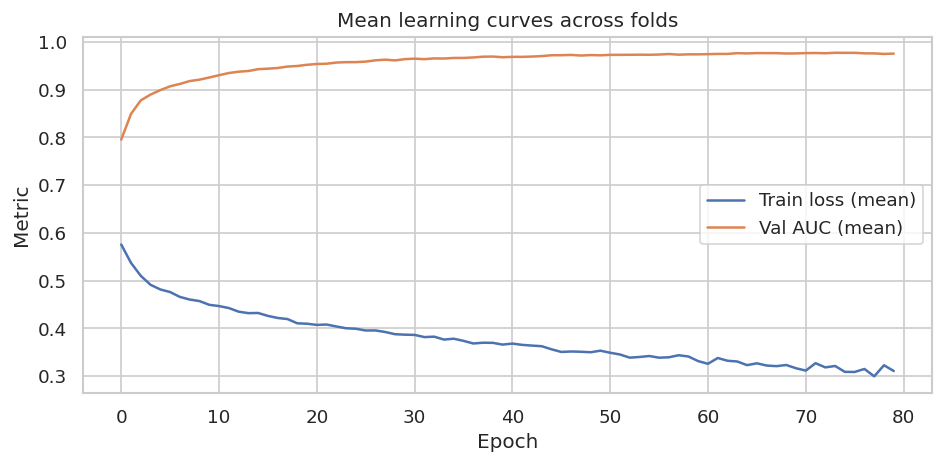

In [ ]:
# Cell 13: improved plotting of fold metrics
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
with open(save_dir/"cv_results.pkl","rb") as f:
    res = pickle.load(f)

# aggregate AUCs
aucs = [r['auc'] for r in res]
plt.figure(figsize=(8,4))
sns.barplot(x=list(range(1,len(aucs)+1)), y=aucs, palette='viridis')
plt.xlabel("Fold"); plt.ylabel("AUC"); plt.title("Fold AUCs")
for i,v in enumerate(aucs):
    plt.text(i, v+0.01, f"{v:.3f}", ha='center')
plt.tight_layout()
plt.savefig(save_dir/"fold_aucs.png", dpi=150)
plt.show()

# show confusion matrix of best fold (heatmap)
best = max(res, key=lambda x: x['auc'])
print("Best fold:", best['fold'], "AUC:", best['auc'])
print("Classification report (best fold):")
print(pd.DataFrame(best['report']).T)
cm = best['cm']
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Pred"); plt.ylabel("True"); plt.title(f"Confusion Matrix (best fold {best['fold']})")
plt.tight_layout()
plt.savefig(save_dir/"best_confusion.png", dpi=150)
plt.show()

# mean learning curves across folds if histories exist
histories = [r.get('history') for r in res if r.get('history') is not None]
if histories:
    import numpy as _np
    max_epochs = max(len(h['train_loss']) for h in histories)
    all_train = _np.array([h['train_loss'] + [ _np.nan ]*(max_epochs - len(h['train_loss'])) for h in histories])
    all_val = _np.array([h['val_auc'] + [ _np.nan ]*(max_epochs - len(h['val_auc'])) for h in histories])
    mean_train = _np.nanmean(all_train, axis=0)
    mean_val = _np.nanmean(all_val, axis=0)
    plt.figure(figsize=(8,4))
    plt.plot(mean_train, label='Train loss (mean)')
    plt.plot(mean_val, label='Val AUC (mean)')
    plt.xlabel('Epoch'); plt.ylabel('Metric'); plt.legend(); plt.title('Mean learning curves across folds')
    plt.tight_layout()
    plt.savefig(save_dir/"learning_curves_mean.png", dpi=150)
    plt.show()


In [ ]:
# Cell 14: final save and example report
print("Best model saved at:", best_overall["model_path"])
# load and show sample predictions with that model (if desired)
final_model = BiLSTMClassifier(INPUT_DIM).to(device)
final_model.load_state_dict(torch.load(best_overall["model_path"]))
final_model.eval()
# Optionally export to ONNX if requested (skipped per choice)


Best model saved at: results_bilstm/best_fold5.pt


/tmp/ipykernel_17202/2083957647.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  final_model.load_state_dict(torch.load(best_overall["model_path"]))


BiLSTMClassifier(
  (lstm): LSTM(28, 128, num_layers=2, batch_first=True, dropout=0.5, bidirectional=True)
  (fc): Sequential(
    (0): Linear(in_features=256, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.5, inplace=False)
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)

Best fold: 5 | AUC: 0.979


/tmp/ipykernel_17202/1300604127.py:28: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


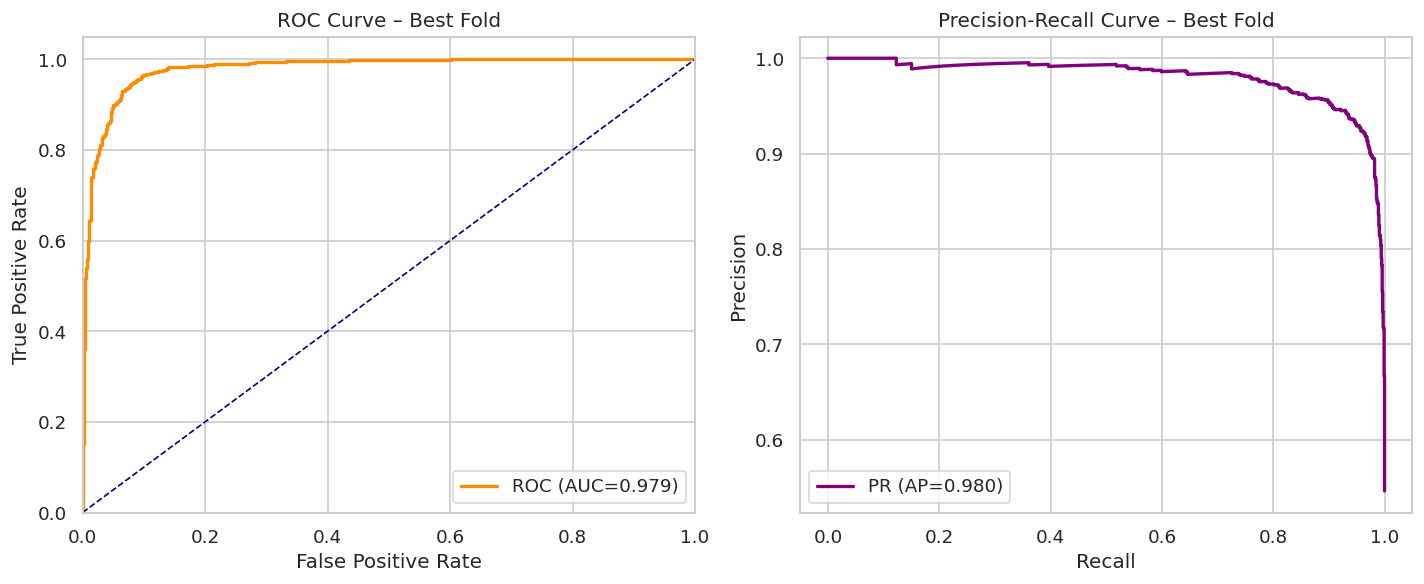

In [ ]:
# Plot ROC and Precision-Recall curve for best fold
import pickle
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

# Load results
with open(save_dir / "cv_results.pkl", "rb") as f:
    res = pickle.load(f)

best = max(res, key=lambda x: x['auc'])
print(f"Best fold: {best['fold']} | AUC: {best['auc']:.3f}")

# Extract test data for best fold using GroupKFold (subject-level split)
from sklearn.model_selection import GroupKFold
groups = np.array(all_subject_idx)
gkf = GroupKFold(n_splits=10)
fold = 0
for train_idx, test_idx in gkf.split(X, y, groups=groups):
    fold += 1
    if fold == best['fold']:
        # fit scaler on the training split of that fold, then transform test
        sc = StandardScaler()
        sc.fit(X[train_idx])
        X_test = sc.transform(X[test_idx])
        y_test = y[test_idx]
        break

# Reload best model
best_model_path = best['model_path']
model = BiLSTMClassifier(X_test.shape[1]).to(device)
model.load_state_dict(torch.load(best_model_path))
model.eval()

with torch.no_grad():
    xb = torch.from_numpy(X_test).to(device).float()
    preds = torch.sigmoid(model(xb)).cpu().numpy().flatten()

fpr, tpr, _ = roc_curve(y_test, preds)
roc_auc = auc(fpr, tpr)
precision, recall, _ = precision_recall_curve(y_test, preds)
ap = average_precision_score(y_test, preds)

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC={roc_auc:.3f})')
plt.plot([0,1], [0,1], color='navy', lw=1, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve – Best Fold')
plt.legend(loc="lower right")
plt.grid(True)

plt.subplot(1,2,2)
plt.plot(recall, precision, color='purple', lw=2, label=f'PR (AP={ap:.3f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve – Best Fold')
plt.legend(loc='lower left')
plt.grid(True)

plt.tight_layout()
plt.savefig(save_dir / "roc_pr_best_fold.png", dpi=150)
plt.show()


Found histories for 10 folds
Fold 1: min_train_epoch=57, max_val_epoch=51, max_val=0.9768, final_val=0.9739, val_drop=0.0029, flag=True
Fold 2: min_train_epoch=60, max_val_epoch=53, max_val=0.9771, final_val=0.9760, val_drop=0.0011, flag=True
Fold 3: min_train_epoch=49, max_val_epoch=46, max_val=0.9757, final_val=0.9752, val_drop=0.0005, flag=True
Fold 4: min_train_epoch=54, max_val_epoch=47, max_val=0.9761, final_val=0.9753, val_drop=0.0008, flag=True
Fold 5: min_train_epoch=76, max_val_epoch=68, max_val=0.9792, final_val=0.9787, val_drop=0.0005, flag=True
Fold 6: min_train_epoch=57, max_val_epoch=49, max_val=0.9770, final_val=0.9763, val_drop=0.0008, flag=True
Fold 7: min_train_epoch=78, max_val_epoch=75, max_val=0.9763, final_val=0.9734, val_drop=0.0029, flag=False
Fold 8: min_train_epoch=53, max_val_epoch=47, max_val=0.9678, final_val=0.9660, val_drop=0.0018, flag=True
Fold 9: min_train_epoch=70, max_val_epoch=72, max_val=0.9784, final_val=0.9778, val_drop=0.0006, flag=True
Fold 10

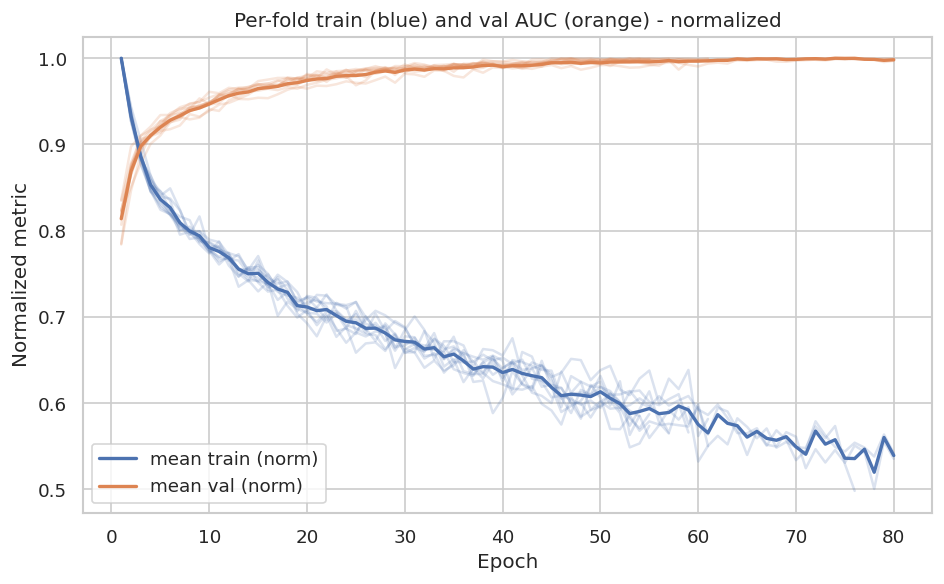

Conclusion: Likely overfitting in 9/10 folds (majority).


In [ ]:
# Overfitting check: per-fold summary and aggregated decision
import numpy as np
import matplotlib.pyplot as plt

histories = [r.get('history') for r in results if r.get('history') is not None]
if not histories:
    print('No training histories available to analyze overfitting.')
else:
    print(f'Found histories for {len(histories)} folds')
    fold_flags = []
    plt.figure(figsize=(8,5))
    for i,h in enumerate(histories):
        tr = np.array(h['train_loss'], dtype=np.float64)
        va = np.array(h['val_auc'], dtype=np.float64)
        epochs = np.arange(1, len(tr)+1)
        # per-fold plot (thin)
        plt.plot(epochs, tr/np.nanmax(tr), color='C0', alpha=0.2)
        plt.plot(epochs, va/np.nanmax(va), color='C1', alpha=0.2)
        # metrics
        min_tr_epoch = int(np.nanargmin(tr))+1
        max_va_epoch = int(np.nanargmax(va))+1
        final_tr = float(tr[-1])
        final_va = float(va[-1])
        max_va = float(np.nanmax(va))
        # heuristics for overfit: validation peak earlier than end and validation drops from peak
        va_drop = max_va - final_va
        gap_epoch = min_tr_epoch - max_va_epoch
        flag = False
        reasons = []
        if va_drop > 0.02:
            flag = True
            reasons.append(f"val drop {va_drop:.3f}")
        if max_va_epoch < len(va) - 5:
            flag = True
            reasons.append(f"val peak early (epoch {max_va_epoch})")
        fold_flags.append((i+1, flag, reasons, {'min_train_epoch':min_tr_epoch,'max_val_epoch':max_va_epoch,'max_val':max_va,'final_val':final_va}))
        print(f"Fold {i+1}: min_train_epoch={min_tr_epoch}, max_val_epoch={max_va_epoch}, max_val={max_va:.4f}, final_val={final_va:.4f}, val_drop={va_drop:.4f}, flag={flag}")
    # mean curves
    max_epochs = max(len(h['train_loss']) for h in histories)
    all_train = np.array([h['train_loss'] + [np.nan]*(max_epochs - len(h['train_loss'])) for h in histories])
    all_val = np.array([h['val_auc'] + [np.nan]*(max_epochs - len(h['val_auc'])) for h in histories])
    mean_train = np.nanmean(all_train, axis=0)
    mean_val = np.nanmean(all_val, axis=0)
    epochs = np.arange(1, len(mean_train)+1)
    plt.plot(epochs, mean_train/np.nanmax(mean_train), label='mean train (norm)', color='C0', lw=2)
    plt.plot(epochs, mean_val/np.nanmax(mean_val), label='mean val (norm)', color='C1', lw=2)
    plt.xlabel('Epoch'); plt.ylabel('Normalized metric'); plt.legend(); plt.title('Per-fold train (blue) and val AUC (orange) - normalized')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # aggregate decision
    flags = [f[1] for f in fold_flags]
    n_flag = sum(flags)
    if n_flag / len(flags) > 0.5:
        print(f"Conclusion: Likely overfitting in {n_flag}/{len(flags)} folds (majority).")
    elif n_flag > 0:
        print(f"Conclusion: Some folds ({n_flag}/{len(flags)}) show signs of overfitting.")
    else:
        print('Conclusion: No strong evidence of overfitting across folds.')
